TOP WORDS PER TOPIC

Topic 1: method, mixed, quantitative, paradigm, reality, purist, many, educational, position, guba

Topic 2: alpha, development, cronbach, instrument, science, reliability, scale, developmental, design, item

Topic 3: triangulation, method, design, denzin, fusch, multiple, bias, participant, source, mixed

TOPIC DISTRIBUTION PER ARTICLE
       Article  Topic 1  Topic 2  Topic 3  Dominant_Topic
research_1.txt    1.000    0.000    0.000               1
research_2.txt    0.046    0.431    0.523               3
research_3.txt    0.000    0.999    0.000               2
research_4.txt    0.000    1.000    0.000               2
research_5.txt    0.000    0.000    0.999               3


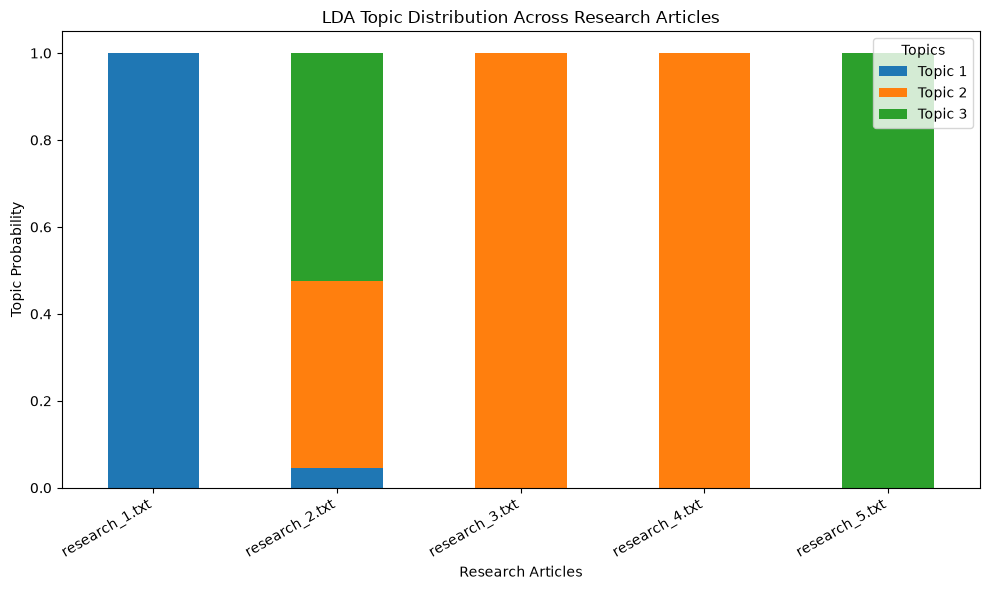

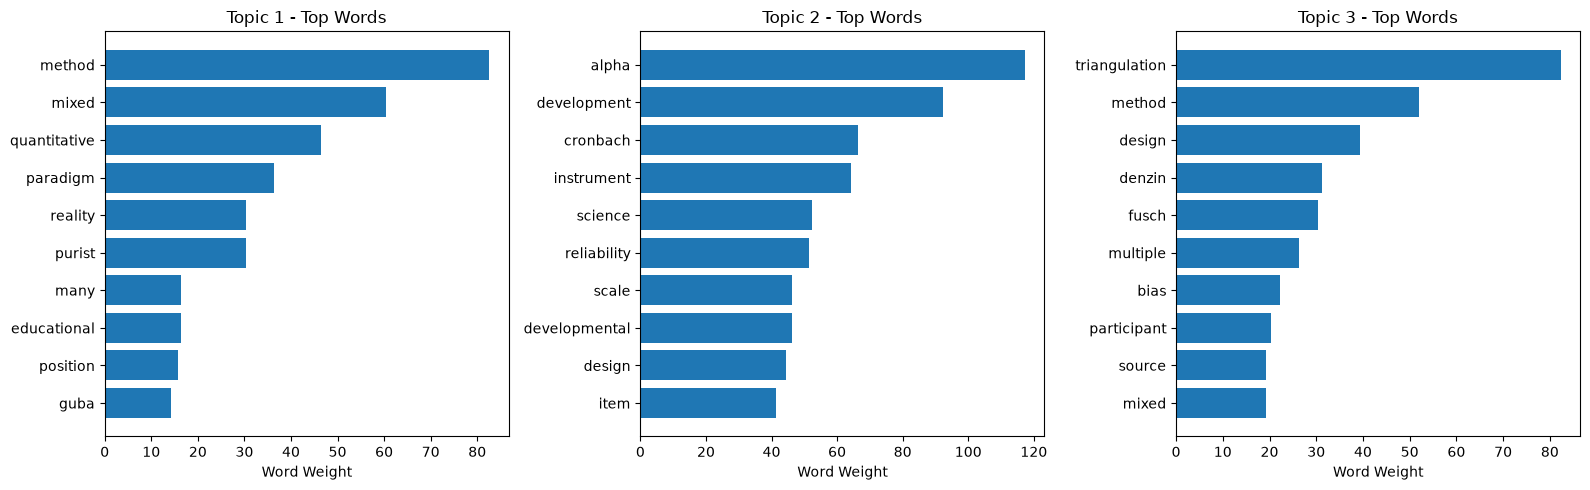


LDA Topic Modelling Completed Successfully!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

if 'df_articles' not in globals():
    df_articles = pd.read_csv('cleaned_research_corpus.csv')

df_articles = df_articles.sort_values(
    'Article'
).reset_index(drop=True)

df_articles = df_articles.dropna(
    subset=['Cleaned_Content']
).copy()

vectorizer = CountVectorizer(
    max_features=1000,
    max_df=0.95,
    min_df=1
)

document_term_matrix = vectorizer.fit_transform(
    df_articles['Cleaned_Content']
)

n_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method='batch',
    max_iter=30
)

topic_distribution = lda_model.fit_transform(
    document_term_matrix
)

feature_names = vectorizer.get_feature_names_out()

print("TOP WORDS PER TOPIC")

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    top_words = [
        feature_names[i]
        for i in top_indices
    ]

    print(
        f"\nTopic {topic_index + 1}:",
        ", ".join(top_words)
    )

topic_columns = [
    f'Topic {i + 1}'
    for i in range(n_topics)
]

topic_df = pd.DataFrame(
    topic_distribution,
    columns=topic_columns
)

topic_df.insert(
    0,
    'Article',
    df_articles['Article'].values
)

topic_df['Dominant_Topic'] = (
    np.argmax(topic_distribution, axis=1) + 1
)

print("\nTOPIC DISTRIBUTION PER ARTICLE")
print(topic_df.round(3).to_string(index=False))

topic_df.set_index('Article')[topic_columns].plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('LDA Topic Distribution Across Research Articles')
plt.xlabel('Research Articles')
plt.ylabel('Topic Probability')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Topics')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(
    1,
    n_topics,
    figsize=(16, 5)
)

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    words = feature_names[top_indices]
    weights = topic[top_indices]

    axes[topic_index].barh(
        words[::-1],
        weights[::-1]
    )

    axes[topic_index].set_title(
        f'Topic {topic_index + 1} - Top Words'
    )

    axes[topic_index].set_xlabel('Word Weight')

plt.tight_layout()
plt.show()

topic_df.to_csv(
    'lda_topic_distribution.csv',
    index=False
)

print("\nLDA Topic Modelling Completed Successfully!")
